# Лабораторная работа №1

## Задания

![Задания](./tasks.png "Задания")

## Библиотеки

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error

## Реализация

### Загрузка данных

In [2]:
df = pd.read_csv("series.csv", parse_dates=["timestamp"])
df.head()

,timestamp,value
0,2026-11-18 00:00:00,101.995074
1,2026-11-18 01:00:00,94.934438
2,2026-11-18 02:00:00,96.359036
3,2026-11-18 03:00:00,69.061720
4,2026-11-18 04:00:00,NaN


### Необходимые преобразования

In [3]:
def adjust_df(df_orig):
    # Сортировка и проверка дубликатов
    df = df_orig.sort_values("timestamp").drop_duplicates("timestamp").set_index("timestamp")

    # Установка временного индекса и проверка частоты
    full_idx = pd.date_range(df.index.min(), df.index.max(), freq="h")
    df = df.reindex(full_idx)
    df.index.name = "timestamp"

    return df

In [4]:
df = adjust_df(df)
df.head()

,value
timestamp,
2026-11-18 00:00:00,101.995074
2026-11-18 01:00:00,94.934438
2026-11-18 02:00:00,96.359036
2026-11-18 03:00:00,69.061720
2026-11-18 04:00:00,NaN


### График всего ряда со скользящим средним и скользящим отклонением

In [5]:
def plot_with_rolling(df_orig):
    df = df_orig.copy()
    df["rolling_mean"] = df["value"].rolling(24).mean()
    df["rolling_std"] = df["value"].rolling(24).std()
    
    plt.figure(figsize=(12, 4))
    plt.plot(df.index, df["value"], label="y")
    plt.plot(df.index, df["rolling_mean"], label="rolling mean")
    plt.plot(df.index, df["rolling_std"], label="rolling std")
    plt.legend()
    plt.show()

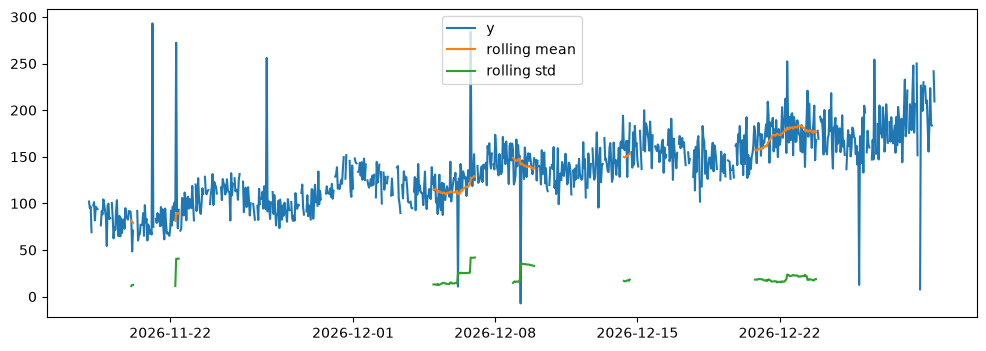

In [6]:
plot_with_rolling(df)

### Отдельный фрагмент

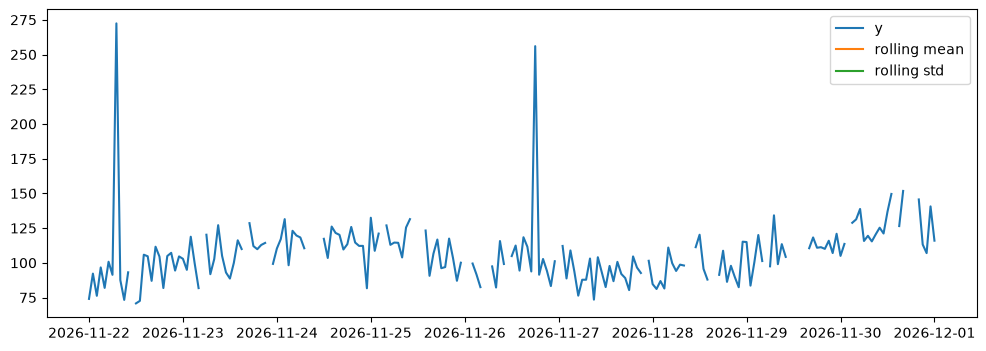

In [7]:
fragment = pd.date_range("2026-11-22", "2026-12-01", freq="h")
plot_with_rolling(df.loc[fragment])

### Сезонные подсерии

По заданию сезонность длится 7 дней, будет 7 подсерий по одной для каждого дня недели, внутри каждой подсерии - 24 часа

In [10]:
def plot_seasonal_subseries(df_orig):
    df = df_orig.copy()
    df["day_of_week"] = df.index.day_of_week
    df["hour"] = df.index.hour
    
    fig, axes = plt.subplots(7, 1, figsize=(15, 20))
    
    for day, ax in enumerate(axes):
        subset = df[df["day_of_week"] == day]  # 0 - понедельник, 1 - вторник и т.д.
    
        sns.lineplot(data=subset, x='hour', y='value', ax=ax, errorbar=None)
    
        ax.set_title(['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'][day])  # чтобы было понятнее
    
        ax.set_xticks(range(24))
    
    plt.tight_layout()
    plt.show()

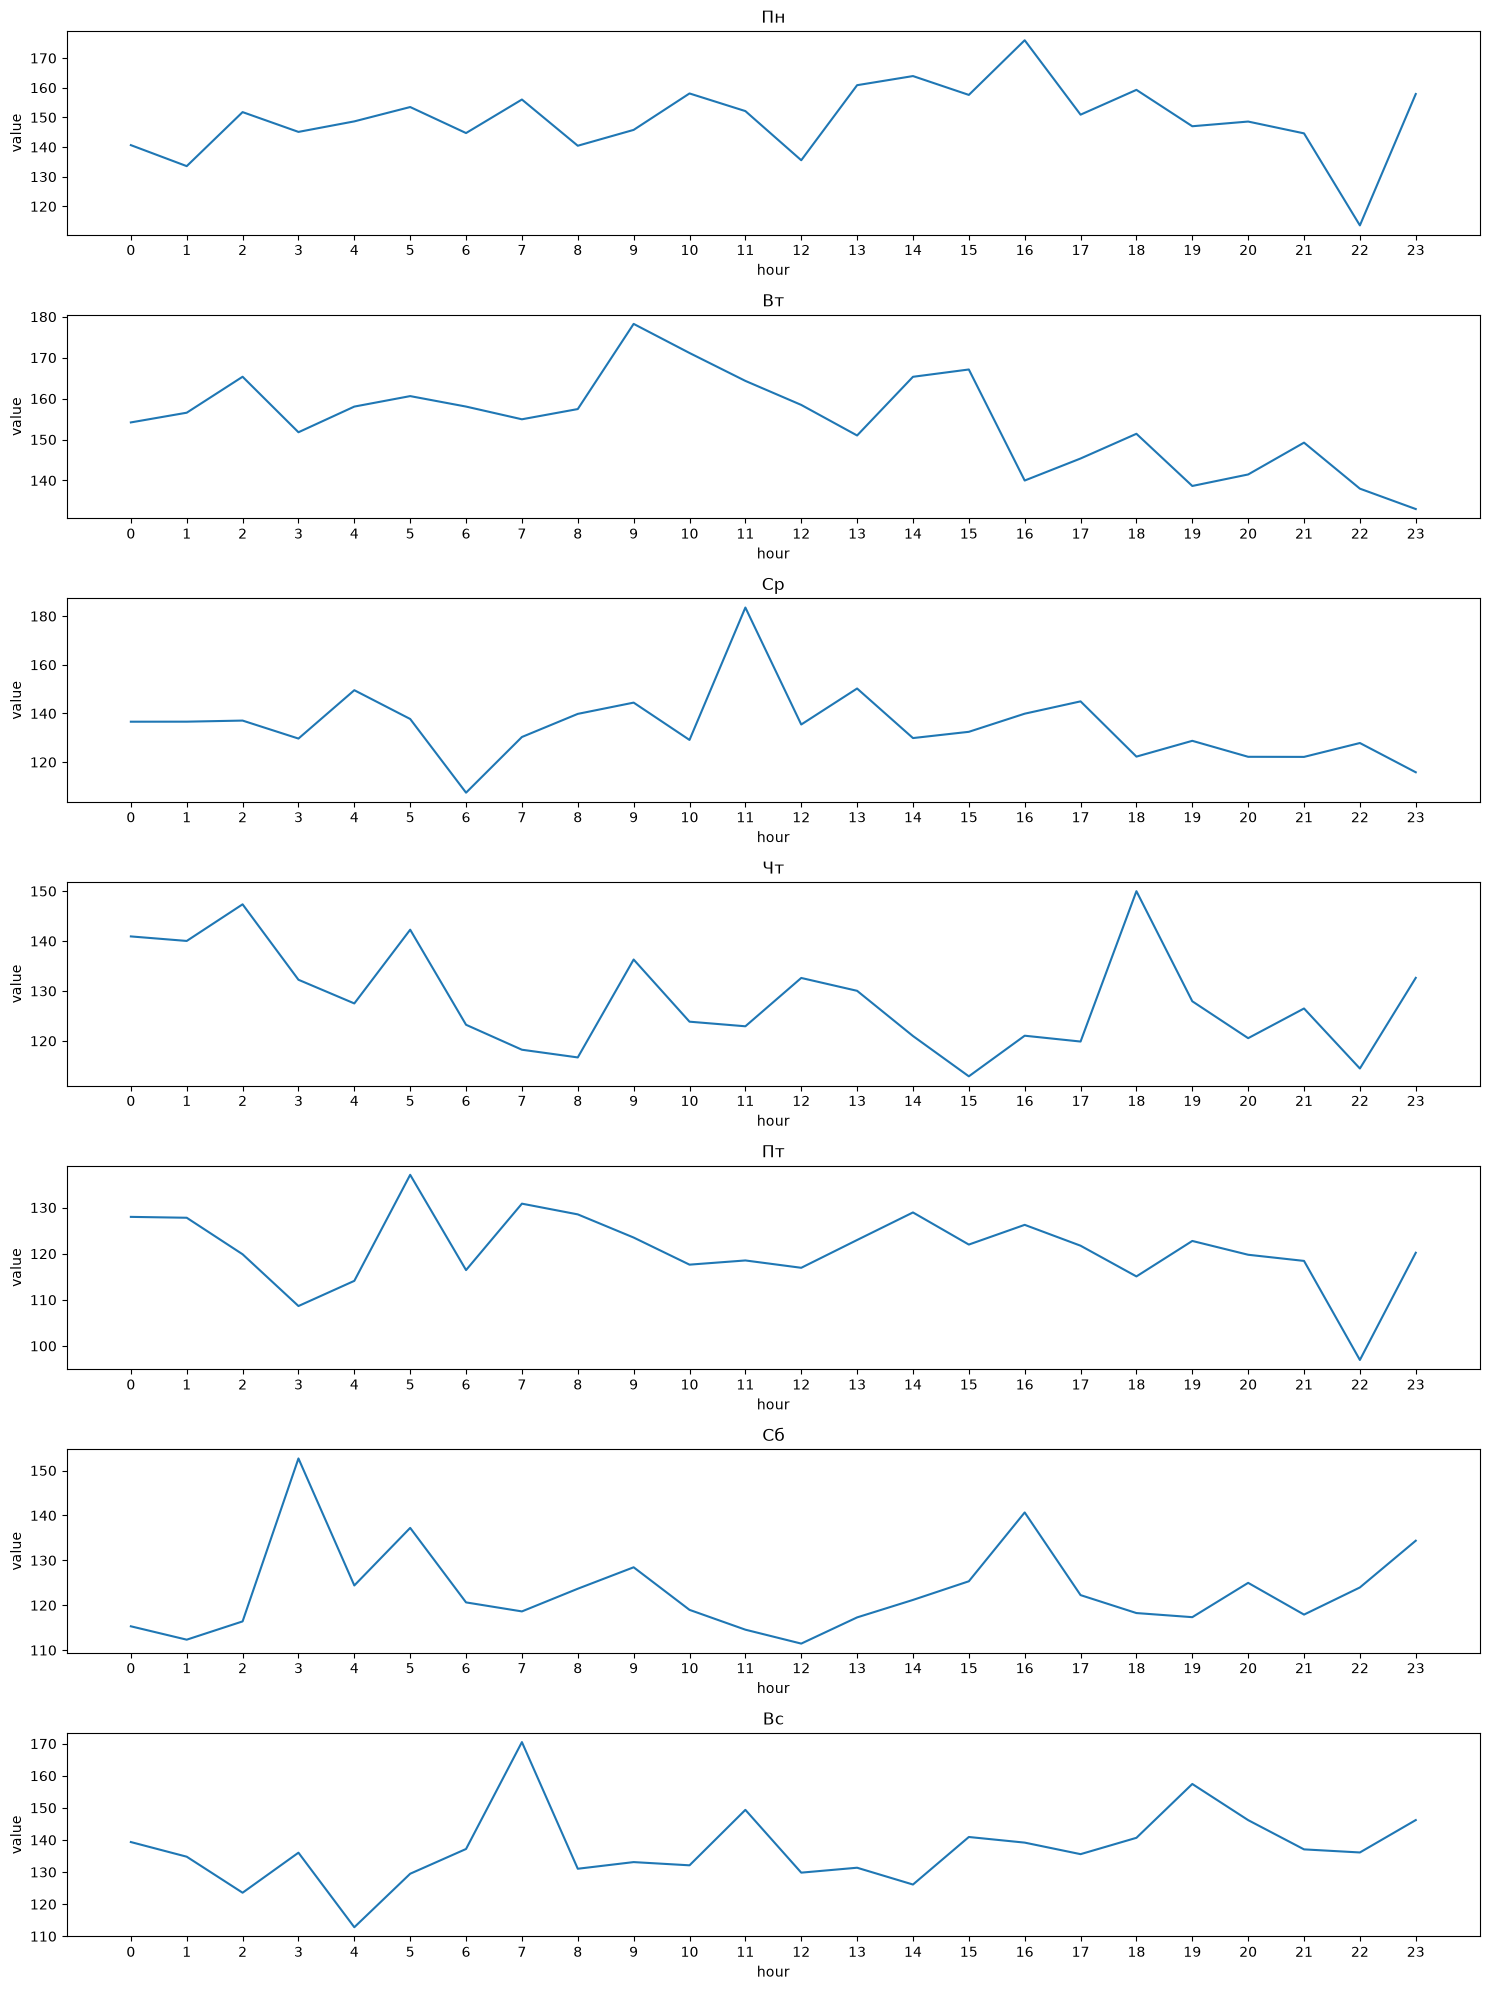

In [11]:
plot_seasonal_subseries(df)

### Тепловая карта "час x день недели"

In [12]:
def plot_heatmap(df_orig):
    df = df_orig.copy()
    df["day_of_week"] = df.index.day_of_week
    df["hour"] = df.index.hour
    
    heatmap_data = df.pivot_table(index='hour', columns='day_of_week', values='value', aggfunc='mean')

    plt.figure(figsize=(10, 10))

    sns.heatmap(heatmap_data, cmap='viridis', annot=False, linewidths=0.5)
    
    plt.xlabel('День недели')
    plt.ylabel('Час')
    
    plt.xticks(ticks=np.arange(7) + 0.5, labels=['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'])
    
    plt.show()

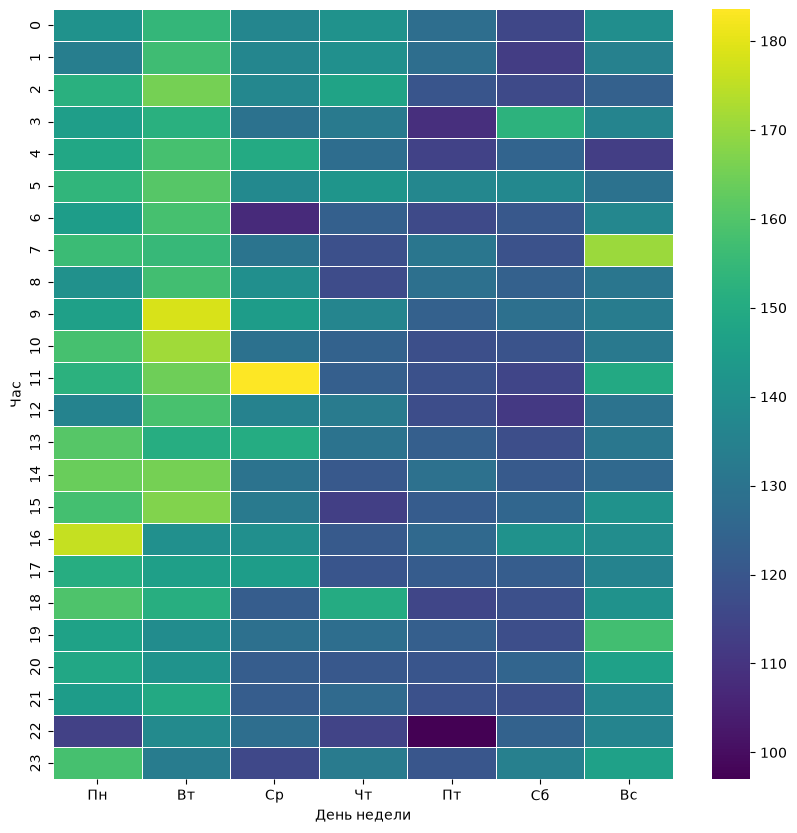

In [13]:
plot_heatmap(df)

### Пропуски

In [14]:
df_gaps = df["value"].isna()

#### Количество

In [15]:
print(df_gaps.sum())

100


#### Где они

In [16]:
df.loc[df_gaps]

,value
timestamp,
2026-11-18 04:00:00,NaN
2026-11-18 11:00:00,NaN
2026-11-18 13:00:00,NaN
2026-11-19 02:00:00,NaN
2026-11-20 05:00:00,NaN
...,...
2026-12-28 17:00:00,NaN
2026-12-28 20:00:00,NaN
2026-12-28 21:00:00,NaN


#### Самая длинная последовательность пропусков

Пояснение:

* `~` даёт отрицание
* `cumsum()` суммирует кумулятивно, если предыдущее и последующее значение одинаковы, тогда это последовательность
* `[df_gaps]` маска по последовательности с исходным DataFrame
* `value_counts()` считаем длину последовательностей
* `max()` возвращаем максимум

In [17]:
print((~df_gaps).cumsum()[df_gaps].value_counts().max())

3


### Импутация

#### Через ffill (берём предыдущее значение)

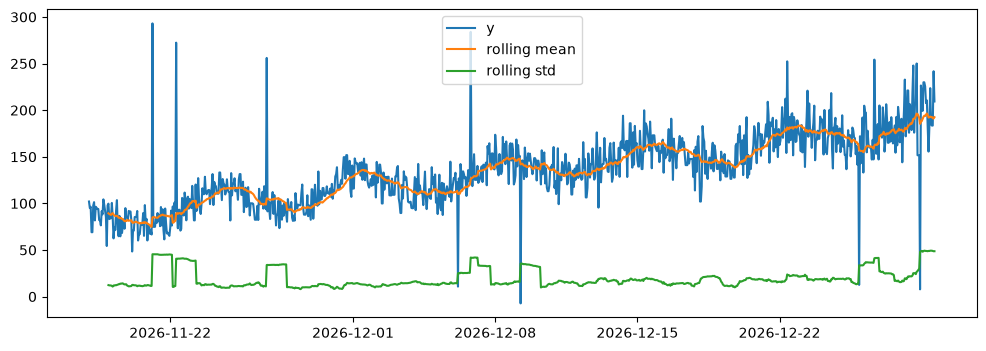

In [18]:
df_ffill = df.ffill()
plot_with_rolling(df_ffill)

#### Линейная интерполяция

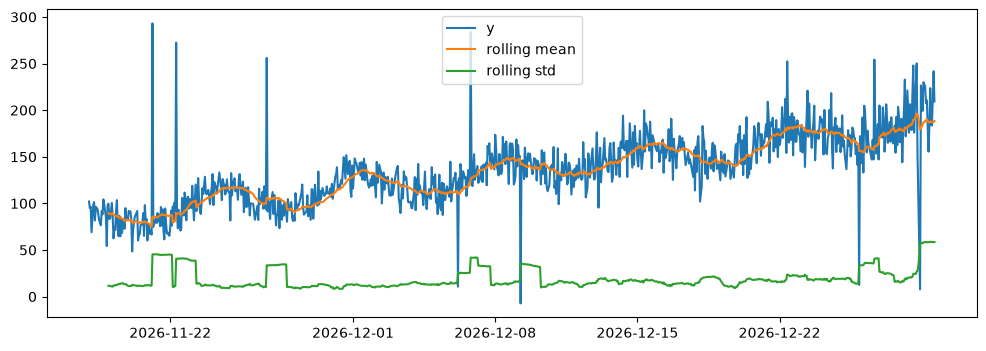

In [19]:
df_lin = df.interpolate(method="linear")  # хотя в качестве метода лучше "time"
plot_with_rolling(df_lin)

#### Медиана (одна на весь ряд, т.к. не требовалось сезонную)

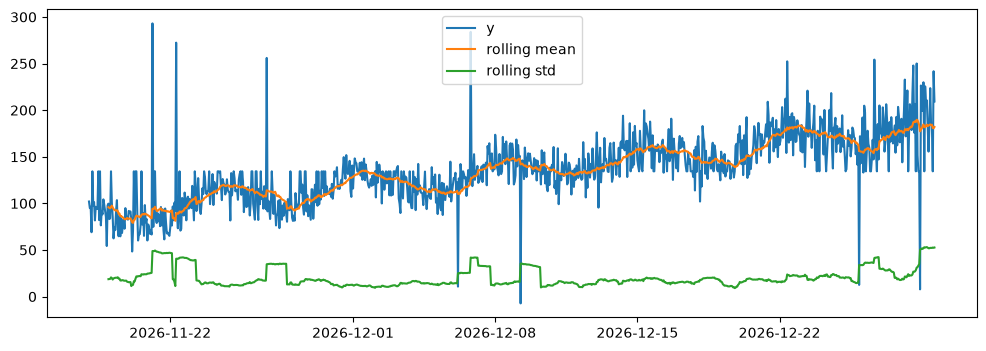

In [21]:
df_med = df.fillna(df.median())
plot_with_rolling(df_med)

#### Сезонный naive

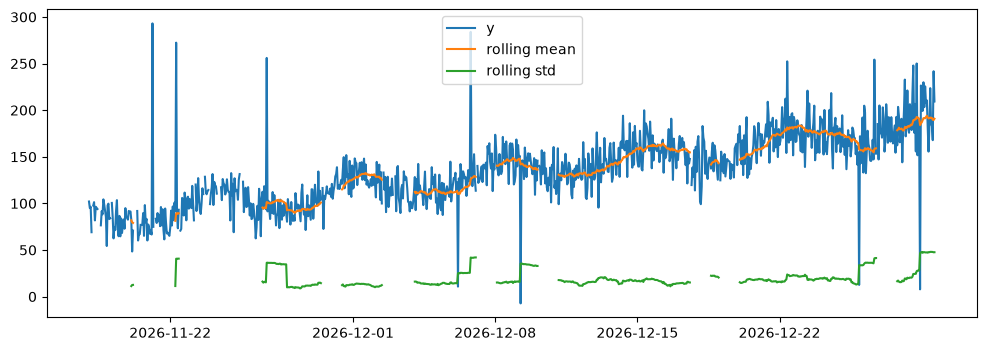

In [22]:
df_naive = df.fillna(df.shift(168))
plot_with_rolling(df_naive)

### Оценка качества импутации

In [59]:
def evaluate_imputation(df_full, df_imputed):
    # Нужно сравнивать только реально восстановленные значения, ибо не все методы их целиком восстанавливают
    comparing = df_imputed.notna()["value"]

    y_true = df_full[comparing]
    y_pred = df_imputed[comparing]

    print("MAE", mean_absolute_error(y_true, y_pred))
    print("RMSE", np.sqrt(mean_squared_error(y_true, y_pred)))

In [60]:
df_full = pd.read_csv("full_series.csv", parse_dates=["timestamp"])
df_full = adjust_df(df_full)

In [61]:
evaluate_imputation(df_full, df_ffill)

MAE 1.709422438831843
RMSE 7.049748747612696


In [62]:
evaluate_imputation(df_full, df_lin)

MAE 1.6606512990009012
RMSE 8.083967960774462


In [63]:
evaluate_imputation(df_full, df_med)

MAE 3.0129931666812384
RMSE 11.539743722101454


In [64]:
evaluate_imputation(df_full, df_naive)

MAE 1.6762427843228975
RMSE 7.535105864789074


Поиск выбросов через IQR

In [27]:
q1, q3 = df["value"].quantile([0.25, 0.75])
iqr = q3 - q1
df["outlier_iqr"] = (df["value"] < q1 - 1.5 * iqr) | (df["value"] > q3 + 1.5 * iqr)
df.head()

,value,outlier_iqr
timestamp,,
2026-11-18 00:00:00,101.995074,False
2026-11-18 01:00:00,94.934438,False
2026-11-18 02:00:00,96.359036,False
2026-11-18 03:00:00,69.061720,False
2026-11-18 04:00:00,NaN,False
